In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the dataset
csv_path = "/content/data.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Could not find the dataset at {csv_path}")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

Dataset shape: (569, 33)

First five rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [3]:

# Remove unnecessary columns if present
df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Check target values
print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts(dropna=False))

# Separate features and target
df = df.dropna(subset=["diagnosis"]).copy()

X = df.drop(columns=["diagnosis"]).apply(
    pd.to_numeric, errors="coerce"
)

y = df["diagnosis"].map({"B": 0, "M": 1})

# Remove rows with invalid target labels, if any
valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

# Report missing feature values before imputation
print("\nMissing feature values:", X.isnull().sum().sum())

print("\nCleaned feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass labels: 0 = Benign, 1 = Malignant")


Duplicate rows: 0

Missing values per column:
diagnosis              0
radius_mean            0
texture_mean           0
perimeter_mean         0
area_mean              0
smoothness_mean        0
compactness_mean       0
concavity_mean         0
concave points_mean    0
symmetry_mean          0
dtype: int64

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing feature values: 0

Cleaned feature shape: (569, 30)
Target shape: (569,)

Class labels: 0 = Benign, 1 = Malignant


Exploratory Data Analysis

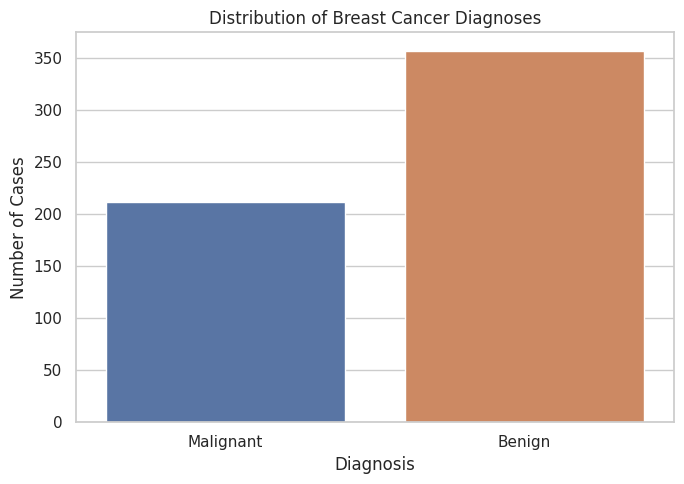

In [4]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
ax = sns.countplot(
    x=y.map({0: "Benign", 1: "Malignant"}),
    hue=y.map({0: "Benign", 1: "Malignant"}),
    legend=False
)
ax.set_title("Distribution of Breast Cancer Diagnoses")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of Cases")
plt.tight_layout()
plt.show()


Histogram-Univariate analysis

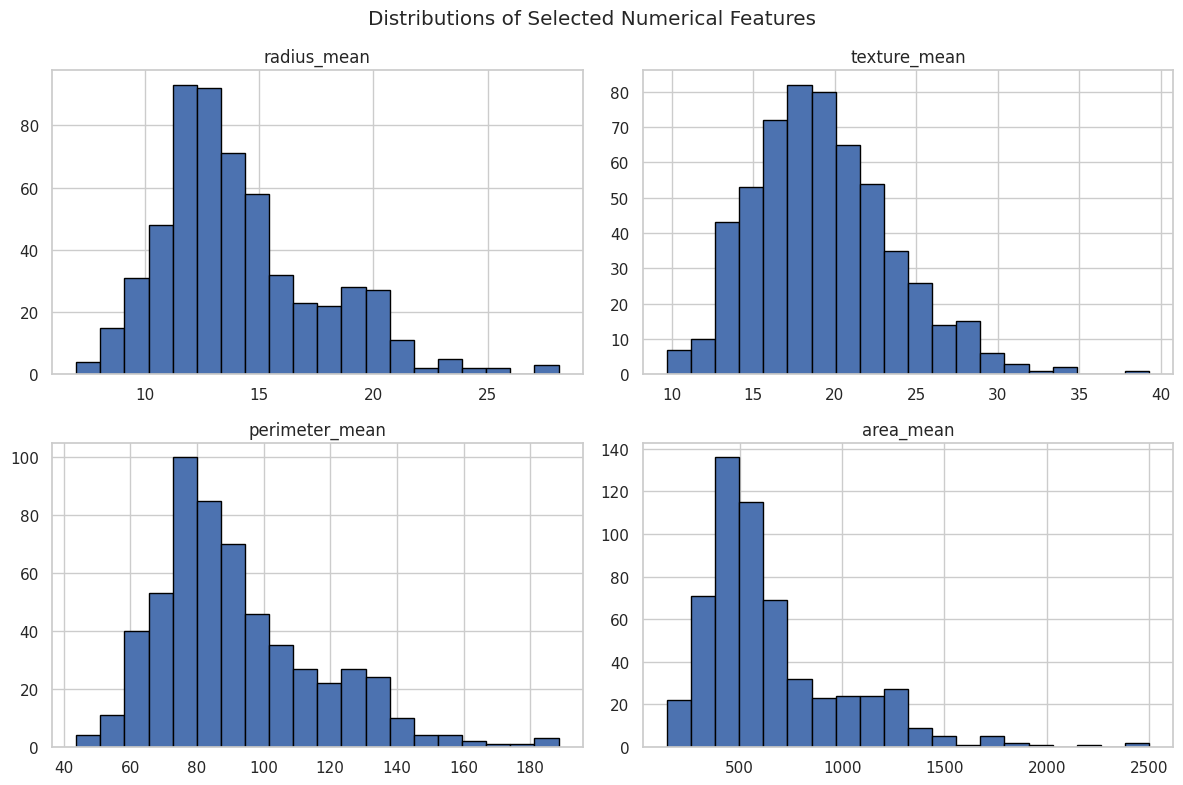

Feature skewness:


,Skewness
radius_mean,0.942380
texture_mean,0.650450
perimeter_mean,0.990650
area_mean,1.645732


In [5]:

selected_features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean"
]

available_features = [
    col for col in selected_features if col in X.columns
]

X[available_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Selected Numerical Features")
plt.tight_layout()
plt.show()

print("Feature skewness:")
display(X[available_features].skew().to_frame("Skewness"))


Boxplots-Outlier analysis

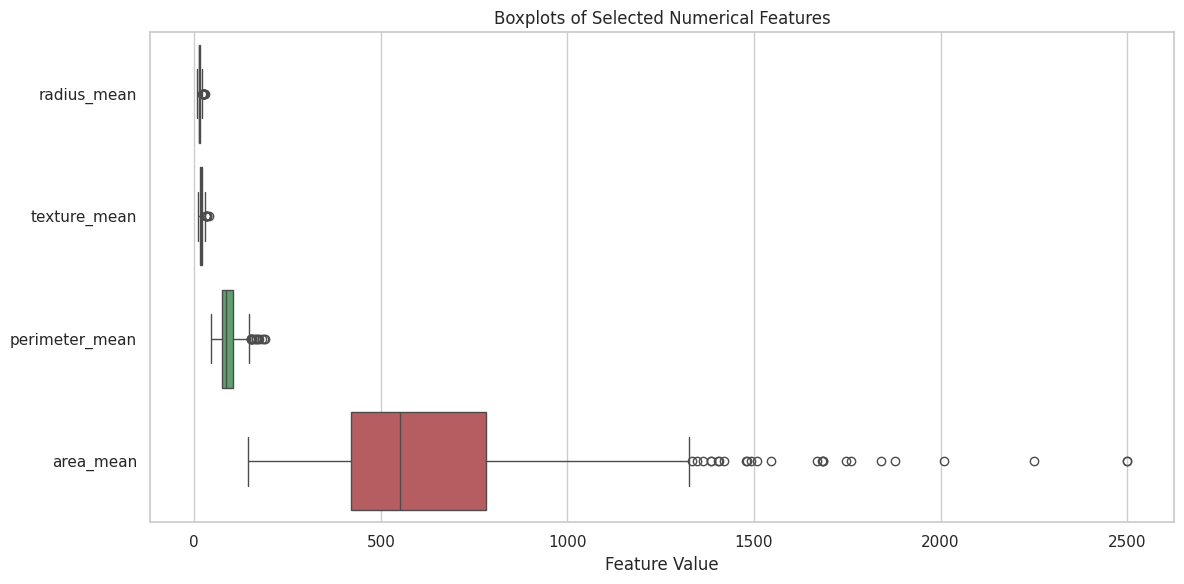

radius_mean: 14 potential outliers
texture_mean: 7 potential outliers
perimeter_mean: 13 potential outliers
area_mean: 25 potential outliers
smoothness_mean: 6 potential outliers
compactness_mean: 16 potential outliers
concavity_mean: 18 potential outliers
concave points_mean: 10 potential outliers
symmetry_mean: 15 potential outliers
fractal_dimension_mean: 15 potential outliers
radius_se: 38 potential outliers
texture_se: 20 potential outliers
perimeter_se: 38 potential outliers
area_se: 65 potential outliers
smoothness_se: 30 potential outliers
compactness_se: 28 potential outliers
concavity_se: 22 potential outliers
concave points_se: 19 potential outliers
symmetry_se: 27 potential outliers
fractal_dimension_se: 28 potential outliers
radius_worst: 17 potential outliers
texture_worst: 5 potential outliers
perimeter_worst: 15 potential outliers
area_worst: 35 potential outliers
smoothness_worst: 7 potential outliers
compactness_worst: 16 potential outliers
concavity_worst: 12 potenti

In [6]:

plt.figure(figsize=(12, 6))

sns.boxplot(data=X[available_features], orient="h")

plt.title("Boxplots of Selected Numerical Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()

# IQR-based outlier counts
for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1

    count = (
        (X[col] < q1 - 1.5 * iqr) |
        (X[col] > q3 + 1.5 * iqr)
    ).sum()

    if count > 0:
        print(f"{col}: {count} potential outliers")


Correlation heatmap

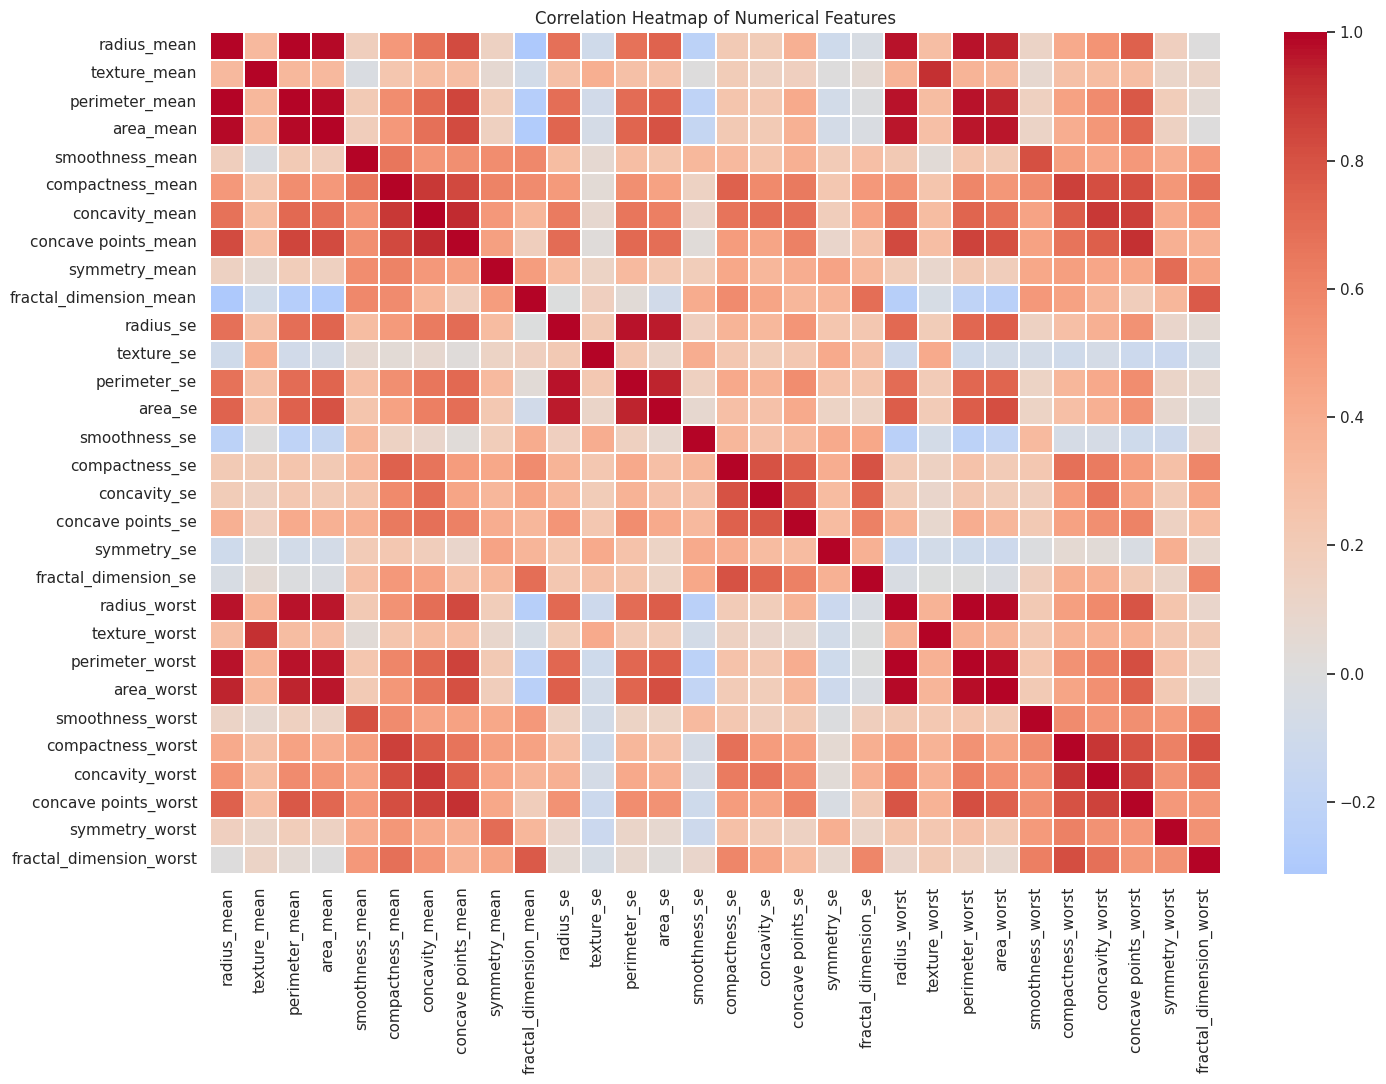

In [7]:

plt.figure(figsize=(15, 11))

correlation = X.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


Scatterplot-Feature relationships

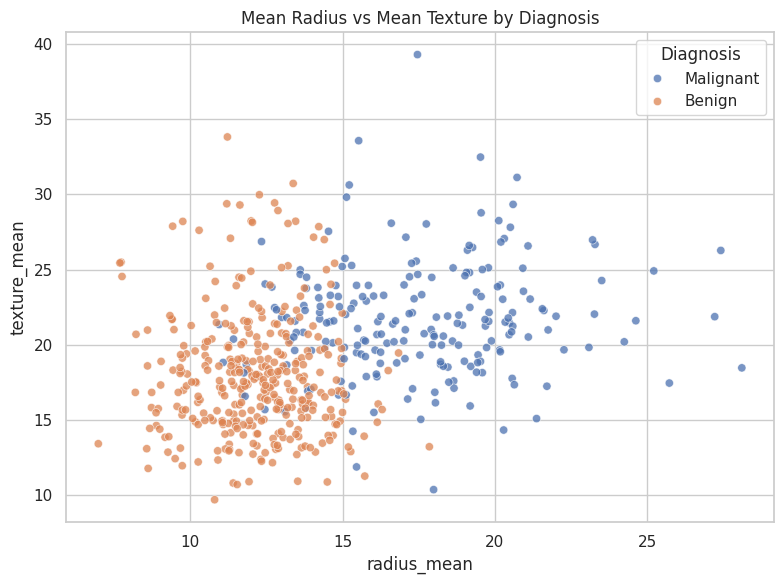

In [8]:

plot_df = X.copy()
plot_df["Diagnosis"] = y.map({
    0: "Benign",
    1: "Malignant"
})

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_df,
    x="radius_mean",
    y="texture_mean",
    hue="Diagnosis",
    alpha=0.75
)

plt.title("Mean Radius vs Mean Texture by Diagnosis")
plt.tight_layout()
plt.show()


Pairplot-Multivariate analysis

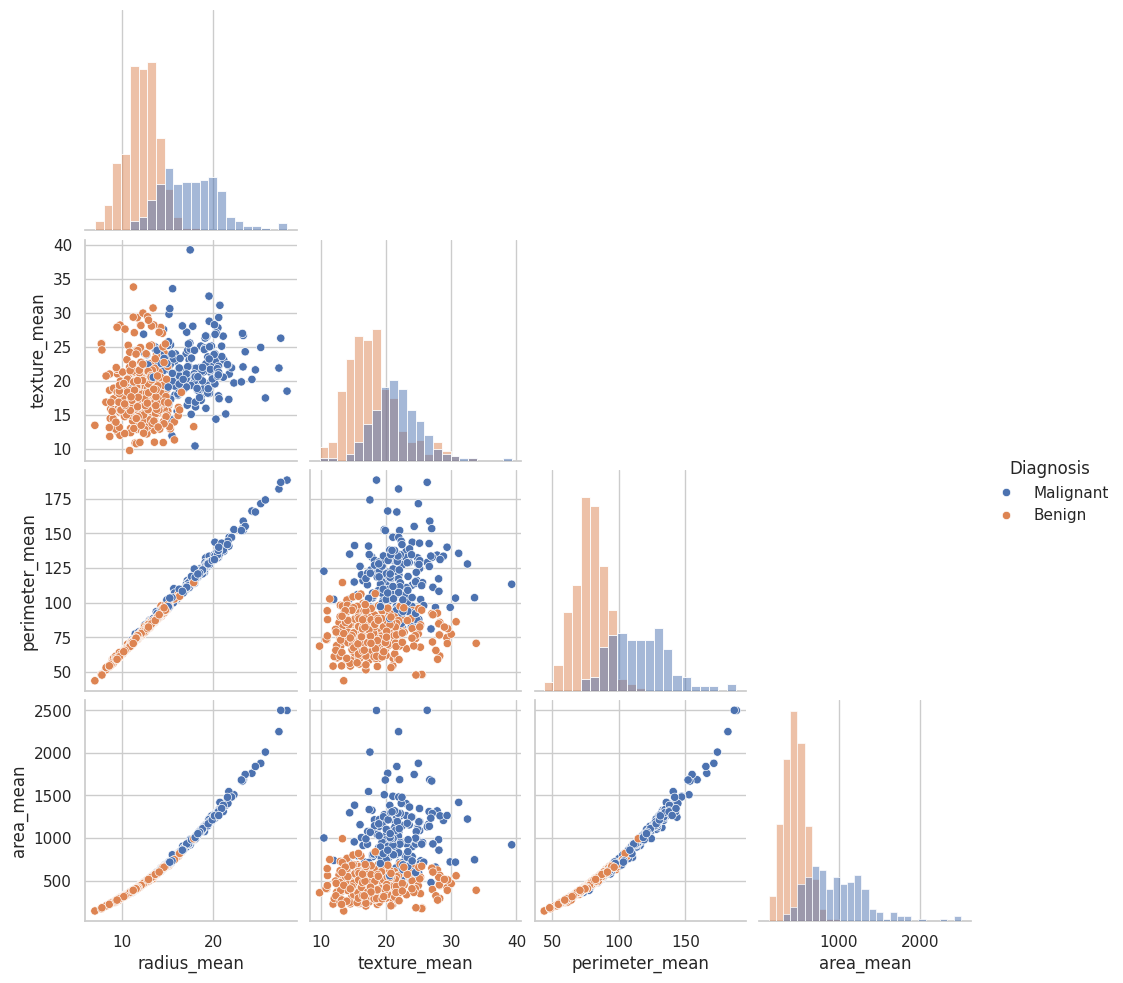

In [9]:

pair_features = [
    col for col in [
        "radius_mean",
        "texture_mean",
        "perimeter_mean",
        "area_mean"
    ]
    if col in X.columns
]

pair_df = X[pair_features].copy()
pair_df["Diagnosis"] = y.map({
    0: "Benign",
    1: "Malignant"
})

sns.pairplot(
    pair_df,
    hue="Diagnosis",
    diag_kind="hist",
    corner=True
)

plt.show()


Compare feature means by diagnosis

Diagnosis,Benign,Malignant
radius_mean,12.146524,17.462830
texture_mean,17.914762,21.604906
perimeter_mean,78.075406,115.365377
area_mean,462.790196,978.376415
smoothness_mean,0.092478,0.102898
compactness_mean,0.080085,0.145188
concavity_mean,0.046058,0.160775
concave points_mean,0.025717,0.087990
symmetry_mean,0.174186,0.192909
fractal_dimension_mean,0.062867,0.062680


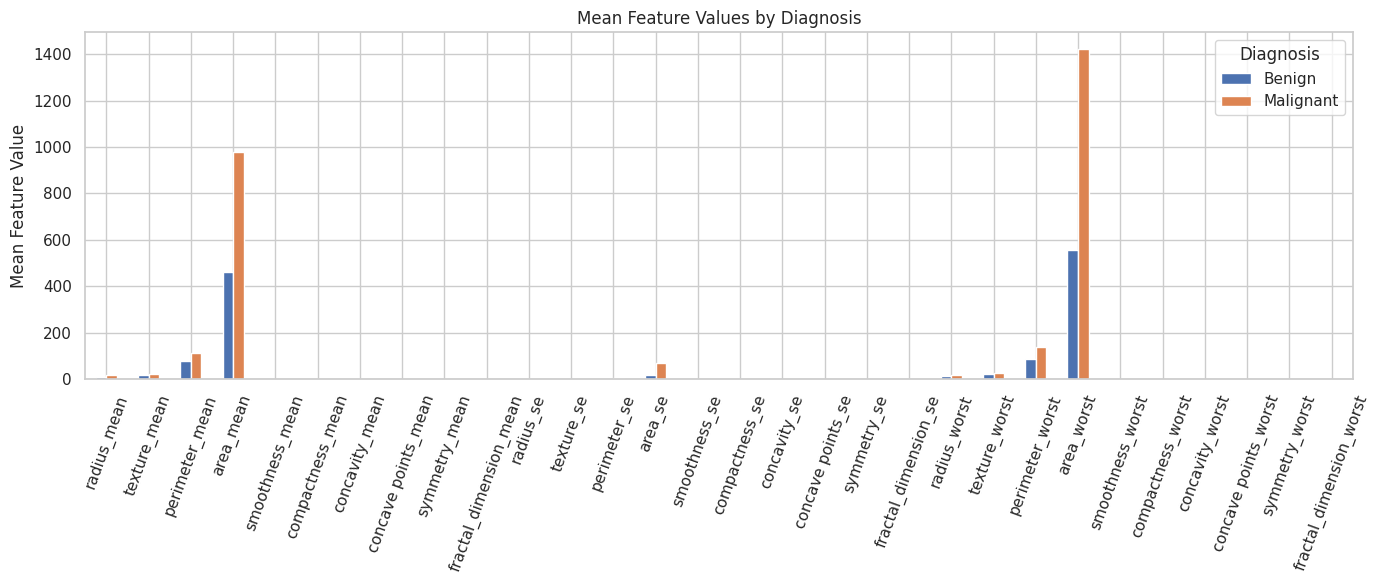

In [10]:

mean_comparison = X.assign(
    Diagnosis=y.map({0: "Benign", 1: "Malignant"})
).groupby("Diagnosis").mean().T

display(mean_comparison)

mean_comparison.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Mean Feature Values by Diagnosis")
plt.ylabel("Mean Feature Value")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()


Split the data and prepare the features

In [11]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Learn imputation values from training data only
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

# Learn scaling parameters from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


Training set: (398, 30)
Validation set: (85, 30)
Test set: (86, 30)


Train the deep learning model

In [12]:

%pip -q install tensorflow


In [13]:

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import roc_auc_score

tf.keras.utils.set_random_seed(42)

def build_model(hidden_units=(32, 16), dropout_rate=0.2):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(hidden_units[0], activation="relu"),
        Dropout(dropout_rate),
        Dense(hidden_units[1], activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )

    return model

configurations = [
    {"units": (32, 16), "dropout": 0.2},
    {"units": (64, 32), "dropout": 0.3}
]

results = []
trained_models = []

for config in configurations:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(
        hidden_units=config["units"],
        dropout_rate=config["dropout"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    val_prob = model.predict(
        X_val_scaled, verbose=0
    ).ravel()

    val_auc = roc_auc_score(y_val, val_prob)

    results.append({
        "Hidden layers": str(config["units"]),
        "Dropout": config["dropout"],
        "Epochs trained": len(history.history["loss"]),
        "Validation AUC": val_auc
    })

    trained_models.append((model, history))

tuning_results = pd.DataFrame(results)
display(tuning_results)

best_index = tuning_results["Validation AUC"].idxmax()
best_model, best_history = trained_models[best_index]

print("Selected configuration:")
print(tuning_results.iloc[best_index])


,Hidden layers,Dropout,Epochs trained,Validation AUC
0,"(32, 16)",0.2,39,0.995873
1,"(64, 32)",0.3,29,0.997052


Selected configuration:
Hidden layers     (64, 32)
Dropout                0.3
Epochs trained          29
Validation AUC    0.997052
Name: 1, dtype: object


Plot training and validation curves

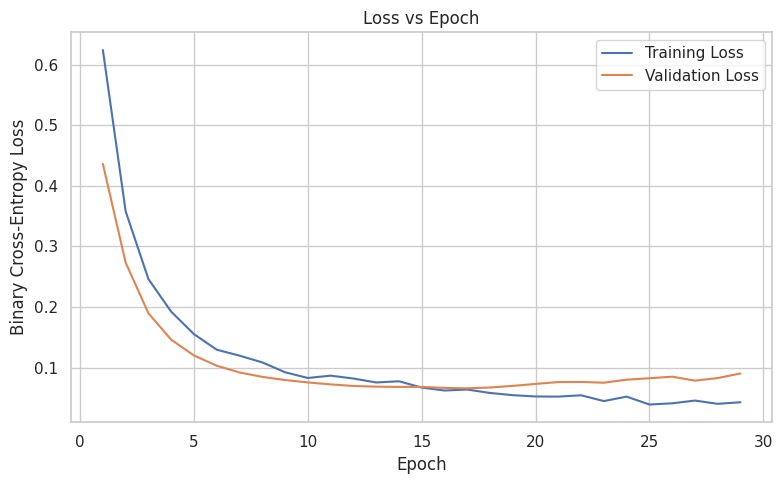

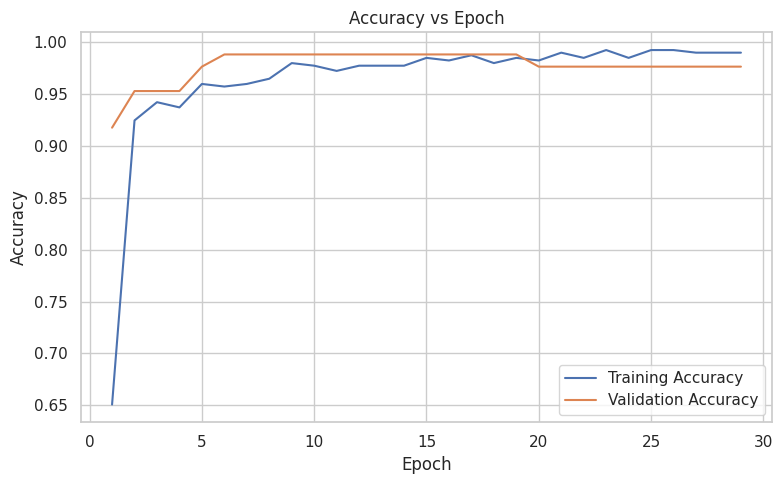

In [14]:

history = best_history.history
epochs = range(1, len(history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["accuracy"], label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.tight_layout()
plt.show()


Evaluate the model on the test set

In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

test_prob = best_model.predict(
    X_test_scaled, verbose=0
).ravel()

test_pred = (test_prob >= 0.5).astype(int)

print("Test Accuracy:", round(
    accuracy_score(y_test, test_pred), 4
))
print("Precision:", round(
    precision_score(y_test, test_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, test_pred, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, test_pred, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_prob), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Test Accuracy: 0.9884
Precision: 1.0
Recall: 0.9688
F1 Score: 0.9841
ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



Confusion Matrix

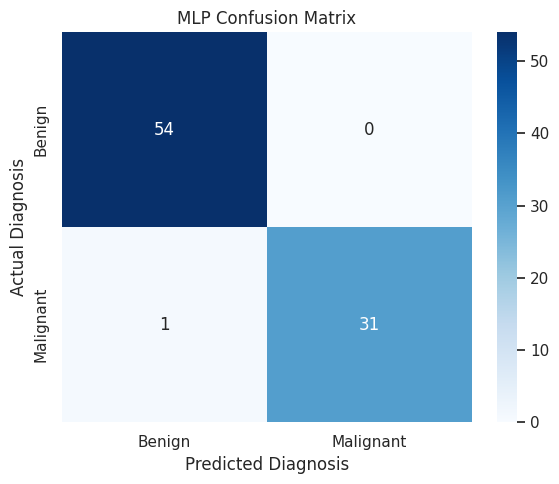

In [16]:

cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.title("MLP Confusion Matrix")
plt.tight_layout()
plt.show()


ROC Curve

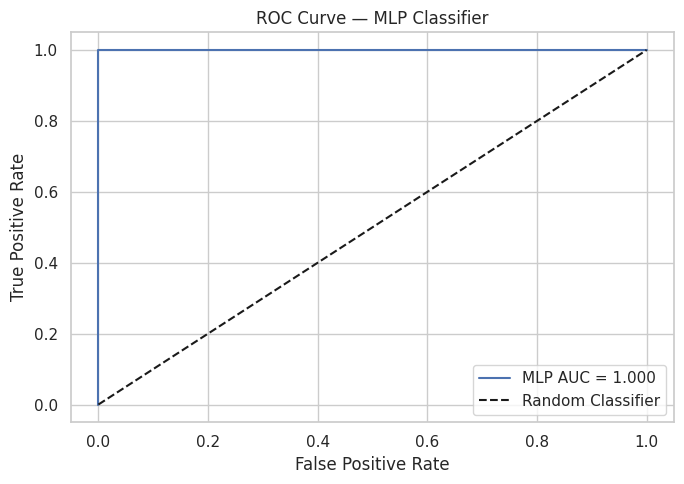

In [17]:

fpr, tpr, thresholds = roc_curve(y_test, test_prob)
test_auc = roc_auc_score(y_test, test_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MLP AUC = {test_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — MLP Classifier")
plt.legend()
plt.tight_layout()
plt.show()


Feature importance

,Feature,AUC Drop
22,perimeter_worst,0.002315
23,area_worst,0.001736
27,concave points_worst,0.001736
28,symmetry_worst,0.001157
0,radius_mean,0.001157
6,concavity_mean,0.000579
26,concavity_worst,0.000579
24,smoothness_worst,0.000579
18,symmetry_se,0.000579
5,compactness_mean,0.000000


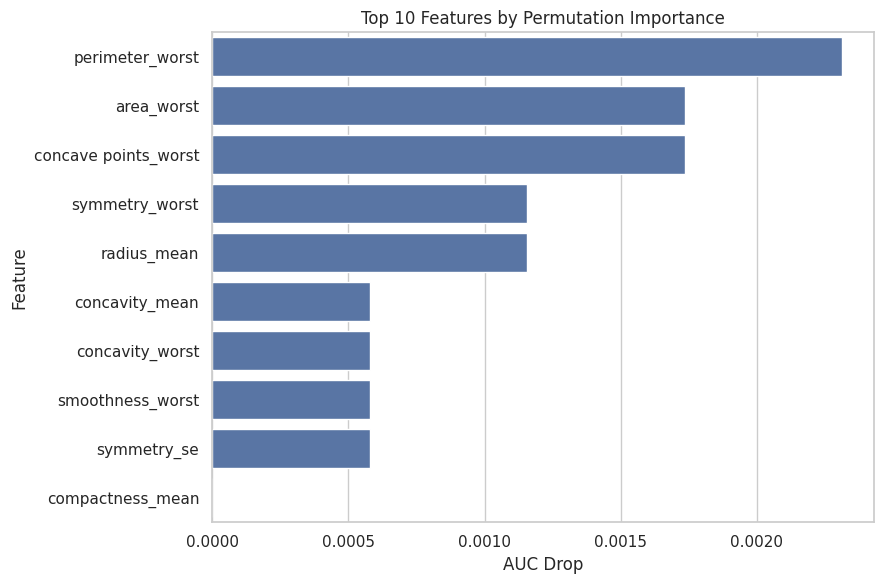

In [18]:

baseline_auc = roc_auc_score(y_test, test_prob)

rng = np.random.default_rng(42)
importance_scores = []

for i, feature in enumerate(X.columns):
    shuffled = X_test_scaled.copy()
    shuffled[:, i] = rng.permutation(shuffled[:, i])

    shuffled_prob = best_model.predict(
        shuffled, verbose=0
    ).ravel()

    shuffled_auc = roc_auc_score(y_test, shuffled_prob)

    importance_scores.append({
        "Feature": feature,
        "AUC Drop": baseline_auc - shuffled_auc
    })

importance_df = pd.DataFrame(importance_scores)
importance_df = importance_df.sort_values(
    "AUC Drop", ascending=False
)

display(importance_df.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x="AUC Drop",
    y="Feature"
)

plt.title("Top 10 Features by Permutation Importance")
plt.tight_layout()
plt.show()


Compare with Logistic Regression

In [20]:

from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(max_iter=2000)
baseline_model.fit(X_train_scaled, y_train)

lr_pred = baseline_model.predict(X_test_scaled)
lr_prob = baseline_model.predict_proba(X_test_scaled)[:, 1]

comparison = pd.DataFrame([
    {
        "Model": "MLP Deep Learning",
        "Accuracy": accuracy_score(y_test, test_pred),
        "F1 Score": f1_score(y_test, test_pred),
        "ROC-AUC": roc_auc_score(y_test, test_prob)
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_pred),
        "F1 Score": f1_score(y_test, lr_pred),
        "ROC-AUC": roc_auc_score(y_test, lr_prob)
    }
])

display(comparison.round(4))


,Model,Accuracy,F1 Score,ROC-AUC
0,MLP Deep Learning,0.9884,0.9841,1.0000
1,Logistic Regression,0.9767,0.9688,0.9988


In [21]:

import os
import shutil

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Save cleaned dataset
df.to_csv("results/cleaned_breast_cancer.csv", index=False)

# Save model results
tuning_results.to_csv("results/hyperparameter_tuning.csv", index=False)
comparison.to_csv("results/model_comparison.csv", index=False)
importance_df.to_csv("results/feature_importance.csv", index=False)

# Save model and preprocessing objects
best_model.save("models/best_mlp_model.keras")

import joblib
joblib.dump(imputer, "models/imputer.pkl")
joblib.dump(scaler, "models/scaler.pkl")

print("Project outputs saved successfully.")


Project outputs saved successfully.
